# DPA Project Volume Part

### Sentinal: Network Intrusion Analysis Using Apache Spark

1. What traffic patterns distinguish normal activity from attacks?
2. Which network services and traffic characteristics are associated with different attack categories?


## Choose the data

- `USE_SUBSET = True`: use the subset CSVs included in `data/subset/`; no download is needed.
- `USE_SUBSET = False`: use all ten original traffic files and the full IANA file.
- `DOWNLOAD_DATA = True`: download the full source files if needed.

We can run this setup cell on the either mode. then the Subset results are for checking the code quickly; use full mode for the final research results. Each mode saves its own outputs in separate folder one mode will not affect the working of other .

After changing `USE_SUBSET`, we have to run all cells again from start so every step uses the same dataset.

In [1]:
# False uses all original traffic files.
USE_SUBSET = True  

# Download the Dataset if needed
# Downloading data will take approximately 30-40 mins (depending on the network speed)
DOWNLOAD_DATA = False 

from pathlib import Path

# checking the project folder when opening from Jupyter.
project_folder = Path.cwd().resolve()
if project_folder.name == "notebooks":
    project_folder = project_folder.parent
elif (project_folder / "DPA-Volume-Part1-Project" / "downloaders").is_dir():
    project_folder = project_folder / "DPA-Volume-Part1-Project"
if not (project_folder / "downloaders" / "download_data.py").is_file():
    raise FileNotFoundError("Open the notebook from the project folder or notebooks/.")

data_folder = project_folder / "data"
parquet_folder = data_folder / "parquet"
reports_folder = project_folder / "reports"
mode = "subset" if USE_SUBSET else "full"

# Keep subset data and results separate from the full run.
if USE_SUBSET:
    traffic_folder = data_folder / "subset"
    traffic_files = sorted(traffic_folder.glob("data network and traffic subset*.csv"))
    iana_file = traffic_folder / "service and port subset.csv"
    parquet_folder = parquet_folder / "subset"
    reports_folder = reports_folder / "subset"
else:
    traffic_folder = data_folder / "Dataset Network Traffic"
    traffic_files = sorted(traffic_folder.glob("*.csv"))
    iana_file = data_folder / "Dataset Service and Port" / "service-names-port-numbers.csv"

print("Data mode:", mode, "| Traffic files:", len(traffic_files))
if DOWNLOAD_DATA:
    import runpy
    downloader = runpy.run_path(str(project_folder / "downloaders" / "download_data.py"))
    downloader["download_traffic"](data_folder)
    downloader["download_iana"](data_folder)
    if not USE_SUBSET:
        traffic_files = sorted(traffic_folder.glob("*.csv"))


Data mode: subset | Traffic files: 10


## Step 1:  Check the source files

Read the headers and the first 500 rows of each netwrok traffic CSV.Then we are reading the whole IANA Service and port CSV.

In [2]:
import csv
from collections import Counter
from itertools import islice

assert len(traffic_files) == 10, f"Expected ten traffic CSVs in {traffic_folder}"
assert iana_file.is_file(), f"IANA file not found: {iana_file}"

for path in traffic_files:
    print(path.name, f"{path.stat().st_size / 1024**3:.2f} GiB")

print(iana_file.name, f"{iana_file.stat().st_size / 1024**2:.2f} MiB")


data network and traffic subset - Friday-02-03-2018.csv 0.03 GiB
data network and traffic subset - Friday-16-02-2018.csv 0.03 GiB
data network and traffic subset - Friday-23-02-2018.csv 0.03 GiB
data network and traffic subset - Thuesday-20-02-2018.csv 0.05 GiB
data network and traffic subset - Thursday-01-03-2018.csv 0.03 GiB
data network and traffic subset - Thursday-15-02-2018.csv 0.03 GiB
data network and traffic subset - Thursday-22-02-2018.csv 0.03 GiB
data network and traffic subset - Wednesday-14-02-2018.csv 0.03 GiB
data network and traffic subset - Wednesday-21-02-2018.csv 0.03 GiB
data network and traffic subset - Wednesday-28-02-2018.csv 0.03 GiB
service and port subset.csv 1.10 MiB


### 1A:  Check the Headers for Network Traffic Data

Checking the no of columns before reading the Network Traffic Data.

In [3]:
# Read the column names before reading the data.
traffic_headers = {}
for path in traffic_files:
    with path.open(encoding="utf-8-sig", newline="") as source:
        header = next(csv.reader(source))
    assert len(header) == len(set(header)), f"Repeated column names: {path.name}"
    traffic_headers[path.name] = header
    print(path.name, len(header), "columns")


data network and traffic subset - Friday-02-03-2018.csv 80 columns
data network and traffic subset - Friday-16-02-2018.csv 80 columns
data network and traffic subset - Friday-23-02-2018.csv 80 columns
data network and traffic subset - Thuesday-20-02-2018.csv 84 columns
data network and traffic subset - Thursday-01-03-2018.csv 80 columns
data network and traffic subset - Thursday-15-02-2018.csv 80 columns
data network and traffic subset - Thursday-22-02-2018.csv 80 columns
data network and traffic subset - Wednesday-14-02-2018.csv 80 columns
data network and traffic subset - Wednesday-21-02-2018.csv 80 columns
data network and traffic subset - Wednesday-28-02-2018.csv 80 columns


### 1B:  Read small samples of Network Traffic Data

Keep the first 500 rows per file total of 5000 records for the reading test in next step.

In [4]:
# Take 500 rows from each file for the reading test.
sample_rows = []
for path in traffic_files:
    with path.open(encoding="utf-8-sig", newline="") as source:
        rows = list(islice(csv.DictReader(source), 500))
    sample_rows.extend(rows)
print("Sample rows:", len(sample_rows))


Sample rows: 5000


### 1C:  Look at the sample values of Network Traffic Data

we are printing the labels, protocol codes, and a few sammple records.

In [5]:
print("Sample labels:", dict(Counter(row["Label"] for row in sample_rows)))
print("Sample protocols:", dict(Counter(row["Protocol"] for row in sample_rows)))
for row in sample_rows[:3]:
    print({name: row[name] for name in ["Dst Port", "Protocol", "Timestamp", "Flow Duration", "Label"]})


Sample labels: {'Benign': 2317, 'Bot': 251, 'DoS attacks-SlowHTTPTest': 402, 'Brute Force -Web': 251, 'Brute Force -XSS': 184, 'SQL Injection': 82, 'DDoS attacks-LOIC-HTTP': 430, 'Label': 1, 'DoS attacks-GoldenEye': 454, 'FTP-BruteForce': 405, 'DDOS attack-LOIC-UDP': 223}
Sample protocols: {'6': 3635, '0': 399, '17': 965, 'Protocol': 1}
{'Dst Port': '443', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:38', 'Flow Duration': '141385', 'Label': 'Benign'}
{'Dst Port': '49684', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:38', 'Flow Duration': '281', 'Label': 'Benign'}
{'Dst Port': '443', 'Protocol': '6', 'Timestamp': '02/03/2018 08:47:40', 'Flow Duration': '279824', 'Label': 'Benign'}


### 1D:  Check IANA Service and Ports Data

We are check the service name, port, and protocol fields. and just checking the missing records before cleaning the data.

In [ ]:
# We are checking and analyzing IANA Data 

with iana_file.open(encoding="utf-8-sig", newline="") as source:
    reader = csv.DictReader(source)
    iana_header = reader.fieldnames
    iana_records = list(reader)
print("IANA rows:", len(iana_records))
print("IANA columns:", iana_header)
assert len(iana_header) == len(set(iana_header)), "Repeated IANA column names"
for name in ["Service Name", "Port Number", "Transport Protocol"]:
    print(name, "missing:", sum(not row[name].strip() for row in iana_records))


IANA rows: 14536
IANA columns: ['Service Name', 'Port Number', 'Transport Protocol', 'Description', 'Assignee', 'Contact', 'Registration Date', 'Modification Date', 'Reference', 'Service Code', 'Unauthorized Use Reported', 'Assignment Notes']
Service Name missing: 1724
Port Number missing: 1073
Transport Protocol missing: 1467


## Step 2:  Define the schemas


### Network Traffic Schema

We will now write the column names and their data types explicitly. For example ports and protocols are integers, counts use long integers, and rates and byte totals use doubles. Dates stay as text until cleaning.

In [ ]:
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, LongType, DoubleType

# True allows missing values; cleaning checks them later.
traffic_schema = StructType([
    StructField("Dst Port", IntegerType(), True),
    StructField("Protocol", IntegerType(), True),
    StructField("Timestamp", StringType(), True),
    StructField("Flow Duration", LongType(), True),
    StructField("Tot Fwd Pkts", LongType(), True),
    StructField("Tot Bwd Pkts", LongType(), True),
    StructField("TotLen Fwd Pkts", DoubleType(), True),
    StructField("TotLen Bwd Pkts", DoubleType(), True),
    StructField("Fwd Pkt Len Max", DoubleType(), True),
    StructField("Fwd Pkt Len Min", DoubleType(), True),
    StructField("Fwd Pkt Len Mean", DoubleType(), True),
    StructField("Fwd Pkt Len Std", DoubleType(), True),
    StructField("Bwd Pkt Len Max", DoubleType(), True),
    StructField("Bwd Pkt Len Min", DoubleType(), True),
    StructField("Bwd Pkt Len Mean", DoubleType(), True),
    StructField("Bwd Pkt Len Std", DoubleType(), True),
    StructField("Flow Byts/s", DoubleType(), True),
    StructField("Flow Pkts/s", DoubleType(), True),
    StructField("Flow IAT Mean", DoubleType(), True),
    StructField("Flow IAT Std", DoubleType(), True),
    StructField("Flow IAT Max", DoubleType(), True),
    StructField("Flow IAT Min", DoubleType(), True),
    StructField("Fwd IAT Tot", DoubleType(), True),
    StructField("Fwd IAT Mean", DoubleType(), True),
    StructField("Fwd IAT Std", DoubleType(), True),
    StructField("Fwd IAT Max", DoubleType(), True),
    StructField("Fwd IAT Min", DoubleType(), True),
    StructField("Bwd IAT Tot", DoubleType(), True),
    StructField("Bwd IAT Mean", DoubleType(), True),
    StructField("Bwd IAT Std", DoubleType(), True),
    StructField("Bwd IAT Max", DoubleType(), True),
    StructField("Bwd IAT Min", DoubleType(), True),
    StructField("Fwd PSH Flags", LongType(), True),
    StructField("Bwd PSH Flags", LongType(), True),
    StructField("Fwd URG Flags", LongType(), True),
    StructField("Bwd URG Flags", LongType(), True),
    StructField("Fwd Header Len", LongType(), True),
    StructField("Bwd Header Len", LongType(), True),
    StructField("Fwd Pkts/s", DoubleType(), True),
    StructField("Bwd Pkts/s", DoubleType(), True),
    StructField("Pkt Len Min", DoubleType(), True),
    StructField("Pkt Len Max", DoubleType(), True),
    StructField("Pkt Len Mean", DoubleType(), True),
    StructField("Pkt Len Std", DoubleType(), True),
    StructField("Pkt Len Var", DoubleType(), True),
    StructField("FIN Flag Cnt", LongType(), True),
    StructField("SYN Flag Cnt", LongType(), True),
    StructField("RST Flag Cnt", LongType(), True),
    StructField("PSH Flag Cnt", LongType(), True),
    StructField("ACK Flag Cnt", LongType(), True),
    StructField("URG Flag Cnt", LongType(), True),
    StructField("CWE Flag Count", LongType(), True),
    StructField("ECE Flag Cnt", LongType(), True),
    StructField("Down/Up Ratio", DoubleType(), True),
    StructField("Pkt Size Avg", DoubleType(), True),
    StructField("Fwd Seg Size Avg", DoubleType(), True),
    StructField("Bwd Seg Size Avg", DoubleType(), True),
    StructField("Fwd Byts/b Avg", DoubleType(), True),
    StructField("Fwd Pkts/b Avg", DoubleType(), True),
    StructField("Fwd Blk Rate Avg", DoubleType(), True),
    StructField("Bwd Byts/b Avg", DoubleType(), True),
    StructField("Bwd Pkts/b Avg", DoubleType(), True),
    StructField("Bwd Blk Rate Avg", DoubleType(), True),
    StructField("Subflow Fwd Pkts", LongType(), True),
    StructField("Subflow Fwd Byts", LongType(), True),
    StructField("Subflow Bwd Pkts", LongType(), True),
    StructField("Subflow Bwd Byts", LongType(), True),
    StructField("Init Fwd Win Byts", LongType(), True),
    StructField("Init Bwd Win Byts", LongType(), True),
    StructField("Fwd Act Data Pkts", LongType(), True),
    StructField("Fwd Seg Size Min", LongType(), True),
    StructField("Active Mean", DoubleType(), True),
    StructField("Active Std", DoubleType(), True),
    StructField("Active Max", DoubleType(), True),
    StructField("Active Min", DoubleType(), True),
    StructField("Idle Mean", DoubleType(), True),
    StructField("Idle Std", DoubleType(), True),
    StructField("Idle Max", DoubleType(), True),
    StructField("Idle Min", DoubleType(), True),
    StructField("Label", StringType(), True),
])

traffic_ip_schema = StructType([
    StructField("Flow ID", StringType(), True),
    StructField("Src IP", StringType(), True),
    StructField("Src Port", IntegerType(), True),
    StructField("Dst IP", StringType(), True),
] + traffic_schema.fields)

print("Original traffic schemas:", len(traffic_schema))


Original traffic schemas: 80


### IANA schema

Read IANA Data and explicitly define the data type we will use text for ports because ports can contain ranges and other columns contain descriptions they will also be text.

In [8]:
# Ports stay as text here because some entries are ranges.
iana_schema = StructType([
    StructField("Service Name", StringType(), True),
    StructField("Port Number", StringType(), True),
    StructField("Transport Protocol", StringType(), True),
    StructField("Description", StringType(), True),
    StructField("Assignee", StringType(), True),
    StructField("Contact", StringType(), True),
    StructField("Registration Date", StringType(), True),
    StructField("Modification Date", StringType(), True),
    StructField("Reference", StringType(), True),
    StructField("Service Code", StringType(), True),
    StructField("Unauthorized Use Reported", StringType(), True),
    StructField("Assignment Notes", StringType(), True),
])

print("IANA schema:", len(iana_schema), "columns")

IANA schema: 12 columns


### Check the Schemas of Network Traffic Files

Column names and order must match each file before Spark reads it because we will be combining these CSV.

In [9]:
# We are checking the column names and their order before using a schema.
traffic_schemas = {}
for file_name, header in traffic_headers.items():
    schema = traffic_ip_schema if "Flow ID" in header else traffic_schema
    assert header == schema.fieldNames(), f"Check the columns in {file_name}"
    traffic_schemas[file_name] = schema
    print(f"Header matches: {file_name} ({len(schema)} columns)")

assert iana_header == iana_schema.fieldNames(), "Check the IANA columns"
print("Header matches: IANA Service and Port Data")


Header matches: data network and traffic subset - Friday-02-03-2018.csv (80 columns)
Header matches: data network and traffic subset - Friday-16-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Friday-23-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Thuesday-20-02-2018.csv (84 columns)
Header matches: data network and traffic subset - Thursday-01-03-2018.csv (80 columns)
Header matches: data network and traffic subset - Thursday-15-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Thursday-22-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Wednesday-14-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Wednesday-21-02-2018.csv (80 columns)
Header matches: data network and traffic subset - Wednesday-28-02-2018.csv (80 columns)
Header matches: IANA Service and Port Data


## Step 3:  Test CSV to Parquet

We are just testing if our CSVs will be stored to Parquet so for this we Use the 5,000 sample rows and the whole IANA file to check reading, types, and Parquet saving before processing all traffic.

### 3A:  Save the samples of Network Traffic Data and Start Spark

we will save only one sample CSV per file just for testing.

In [10]:
sample_folder = data_folder / "samples" / mode
sample_folder.mkdir(parents=True, exist_ok=True)

# Read fresh samples from the selected files, even if the data mode changed.
sample_rows = []
traffic_headers = {}
traffic_schemas = {}
for path in traffic_files:
    with path.open(encoding="utf-8-sig", newline="") as source:
        reader = csv.DictReader(source)
        header = reader.fieldnames
        rows = list(islice(reader, 500))
    schema = traffic_ip_schema if "Flow ID" in header else traffic_schema
    assert header == schema.fieldNames(), f"Check the columns in {path.name}"
    traffic_headers[path.name] = header
    traffic_schemas[path.name] = schema
    sample_rows.extend(rows)
    with (sample_folder / path.name).open("w", encoding="utf-8", newline="") as output:
        writer = csv.DictWriter(output, fieldnames=header)
        writer.writeheader()
        writer.writerows(rows)

import os
# Use the same Spark settings inside and outside Docker.
os.environ.setdefault("SPARK_CONF_DIR", str(project_folder / "config"))
from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)
print("Sample traffic records:", len(sample_rows))


Spark version: 4.2.0
Sample traffic records: 5000


### 3B:  Read the datasets

We are reading the both dataset using the explicit schemas that we have defined earlier

In [11]:
# We will Keep badly formatted rows means the dirty records so we can count them during cleaning and so that we can support our analysis.
sample_parts = []
for path in traffic_files:
    schema = StructType(traffic_schemas[path.name].fields + [StructField("_corrupt_record", StringType(), True)])
    part = (spark.read.schema(schema)
             .option("header", True).option("enforceSchema", False)
             .option("mode", "PERMISSIVE").option("escape", '"')
             .csv(str(sample_folder / path.name)))
    sample_parts.append(part)

sample_traffic = sample_parts[0]
for part in sample_parts[1:]:
    sample_traffic = sample_traffic.unionByName(part, allowMissingColumns=True)

iana_read_schema = StructType(iana_schema.fields + [StructField("_corrupt_record", StringType(), True)])
iana_source = (spark.read.schema(iana_read_schema)
           .option("header", True).option("enforceSchema", False)
           .option("mode", "PERMISSIVE").option("escape", '"')
           .option("columnNameOfCorruptRecord", "_corrupt_record")
           .option("multiLine", True).csv(str(iana_file)))

sample_traffic = sample_traffic.toDF(*[name.lower().replace(" ", "_").replace("/", "_") for name in sample_traffic.columns])
iana_source = iana_source.toDF(*[name.lower().replace(" ", "_") for name in iana_source.columns])

sample_traffic.select("dst_port", "protocol", "flow_duration", "label").printSchema()
sample_traffic.select("dst_port", "protocol", "flow_duration", "label").show(5)


root
 |-- dst_port: integer (nullable = true)
 |-- protocol: integer (nullable = true)
 |-- flow_duration: long (nullable = true)
 |-- label: string (nullable = true)

+--------+--------+-------------+------+
|dst_port|protocol|flow_duration| label|
+--------+--------+-------------+------+
|     443|       6|       141385|Benign|
|   49684|       6|          281|Benign|
|     443|       6|       279824|Benign|
|     443|       6|          132|Benign|
|     443|       6|       274016|Benign|
+--------+--------+-------------+------+
only showing top 5 rows


### 3C: Save and check Parquet for Both Dataset

We are saving the CSV using parquet and we are reading it again to check if counts have changed or any datatype has changed or not.

In [12]:
sample_tables = parquet_folder / "sample"
sample_traffic.write.mode("overwrite").parquet(str(sample_tables / "traffic"))
iana_source.write.mode("overwrite").parquet(str(sample_tables / "iana"))

# Read the saved tables back to check their counts and types.
traffic_parquet = spark.read.parquet(str(sample_tables / "traffic"))
iana_parquet = spark.read.parquet(str(sample_tables / "iana"))

for name, original, restored, expected in [
    ("Traffic", sample_traffic, traffic_parquet, len(sample_rows)),
    ("IANA", iana_source, iana_parquet, len(iana_records)),
]:
    actual = restored.count()
    assert actual == expected, f"{name}: row count changed"
    assert original.dtypes == restored.dtypes, f"{name}: column types changed"
    print(f"{name}: {actual} rows; types preserved.")

print("Step 3 passed. Parquet saved in:", sample_tables)
print("Malformed sample rows:", traffic_parquet.filter("_corrupt_record IS NOT NULL").count())


Traffic: 5000 rows; types preserved.
IANA: 14536 rows; types preserved.
Step 3 passed. Parquet saved in: /home/jovyan/Dpa-Cybersecurity-Analysis/data/parquet/subset/sample
Malformed sample rows: 1


## Step 4:  Read and clean the data

We will read all the Network Traffic CSVs and IANA service and port dataset and get it read for cleaning. we will use parquet to process the records faster.

### 4A:  Read all files and save raw Parquet

We are checking all CSV fields, and keep `source_file` to identify each day's records and then we will save them as raw parquet.

In [13]:
from pyspark.sql import functions as F
from pyspark import StorageLevel

# We are Checking every CSV column when looking for badly formatted rows and dirty records.
spark.conf.set("spark.sql.csv.parser.columnPruning.enabled", "false")
traffic_parts = []
for path in traffic_files:
    schema = StructType(traffic_schemas[path.name].fields + [StructField("_corrupt_record", StringType(), True)])
    part = (spark.read.schema(schema)
             .option("header", True).option("enforceSchema", False)
             .option("mode", "PERMISSIVE").option("escape", '"')
             .option("columnNameOfCorruptRecord", "_corrupt_record")
             .csv(str(path)).withColumn("source_file", F.lit(path.name)))
    traffic_parts.append(part)
traffic_source = traffic_parts[0]
for part in traffic_parts[1:]:
    traffic_source = traffic_source.unionByName(part, allowMissingColumns=True)
traffic_source = traffic_source.toDF(*[column.lower().replace(" ", "_").replace("/", "_") for column in traffic_source.columns])

# we are Saving the raw tables before applying any cleaning.
raw_folder = parquet_folder / "raw"
traffic_source.write.mode("overwrite").parquet(str(raw_folder / "traffic"))
iana_source.write.mode("overwrite").parquet(str(raw_folder / "iana"))
raw_traffic = spark.read.parquet(str(raw_folder / "traffic"))
raw_iana = spark.read.parquet(str(raw_folder / "iana"))
print("Traffic files processed:", len(traffic_files))
raw_traffic.groupBy("source_file").count().orderBy("source_file").show(truncate=False)


Traffic files processed: 10
+----------------------------------------------------------+------+
|source_file                                               |count |
+----------------------------------------------------------+------+
|data network and traffic subset - Friday-02-03-2018.csv   |100369|
|data network and traffic subset - Friday-16-02-2018.csv   |100269|
|data network and traffic subset - Friday-23-02-2018.csv   |100509|
|data network and traffic subset - Thuesday-20-02-2018.csv |100394|
|data network and traffic subset - Thursday-01-03-2018.csv |100289|
|data network and traffic subset - Thursday-15-02-2018.csv |100452|
|data network and traffic subset - Thursday-22-02-2018.csv |100476|
|data network and traffic subset - Wednesday-14-02-2018.csv|100449|
|data network and traffic subset - Wednesday-21-02-2018.csv|100263|
|data network and traffic subset - Wednesday-28-02-2018.csv|100370|
+----------------------------------------------------------+------+



### Keep the cleaning counts

In this section we are just maintaining the count before the cleaning of that so that we can count how much data is cleaned till the end.

In [14]:
audit_rows = []

# Save the rows removed or changed after each step.
def record_step(dataset, step, before, after, reason, modified=0):
    audit_rows.append((dataset, step, before, before - after, modified, after, reason))
    print(f"{dataset} | {step}: {before:,} -> {after:,}; removed {before - after:,}; modified {modified:,}")
    return after

traffic = raw_traffic
iana = raw_iana
traffic_count = traffic.count()
iana_count = iana.count()
print(f"Input rows: traffic={traffic_count:,}, IANA={iana_count:,}")


Input rows: traffic=1,003,840, IANA=14,536


### 4B:  Remove badly formatted CSV records

Check both traffic and IANA. we are removing the wows with too many or too few fields do not match the schema because Network Traffic can also have invalid numbers. as we have records of dirty data while cleaning so we are cleaning them as it does not matched the schema.

In [15]:
# Remove rows that do not match the CSV schema.
traffic = traffic.filter(F.col("_corrupt_record").isNull()).drop("_corrupt_record")
traffic_count = record_step("traffic", "Malformed records", traffic_count, traffic.count(),
                            "Remove CSV structure or numeric parsing failures; raw evidence retained")
iana = iana.filter(F.col("_corrupt_record").isNull()).drop("_corrupt_record")
iana_count = record_step("iana", "Malformed records", iana_count, iana.count(),
                         "Remove CSV rows with the wrong number of fields; raw text is retained")


traffic | Malformed records: 1,003,840 -> 1,003,781; removed 59; modified 0
iana | Malformed records: 14,536 -> 14,536; removed 0; modified 0


### 4C:  Remove duplicate records

We are comparing all typed source columns before dropping any columns. we will just keep one copy per traffic file and one copy of each IANA row.

In [16]:
# Check duplicates before dropping any columns.
traffic = traffic.dropDuplicates().persist(StorageLevel.DISK_ONLY)
traffic_count = record_step("traffic", "Duplicate records", traffic_count, traffic.count(),
                            "Keep one matching typed source record per file, comparing all source columns")
iana = iana.dropDuplicates()
iana_count = record_step("iana", "Duplicate records", iana_count, iana.count(),
                         "Keep one copy of each complete registry record")


traffic | Duplicate records: 1,003,781 -> 987,841; removed 15,940; modified 0
iana | Duplicate records: 14,536 -> 14,536; removed 0; modified 0


### 4D:  Keep the columns needed for analysis

We will only use the columns that are needed for Network Traffic analysis we will Keep traffic labels, times, measurements, port, protocol, and filename. For IANA, keep service name, port, and protocol. Raw Parquet still has all columns.

In [17]:
#Keep the columns that are usable for us during network traffic analysis
traffic_columns = ["dst_port", "protocol", "timestamp", "flow_duration", "tot_fwd_pkts", "tot_bwd_pkts",
                    "totlen_fwd_pkts", "totlen_bwd_pkts", "flow_byts_s", "flow_pkts_s", "label"]
unique_traffic = traffic
selected_traffic = unique_traffic.select(*traffic_columns, "source_file").persist(StorageLevel.DISK_ONLY)
traffic = selected_traffic
traffic_count = record_step("traffic", "Select analysis columns", traffic_count, traffic.count(),
                            "Keep 11 research fields and source_file; raw table retains all columns")
unique_traffic.unpersist()
iana = iana.select("service_name", "port_number", "transport_protocol")
iana_count = record_step("iana", "Select lookup columns", iana_count, iana_count,
                         "Keep service name, port number, and transport protocol")


traffic | Select analysis columns: 987,841 -> 987,841; removed 0; modified 0
iana | Select lookup columns: 14,536 -> 14,536; removed 0; modified 0


### 4E:  Fix text formats

in this section we are Triming spaces, turn empty text into null, and lowercase IANA protocol names so the join keys match. Keep the supplied attack-label spelling. we are doing this match the joining condition and have consistent data.

In [18]:
# Remove extra spaces, turn blank text into null and lowercase IANA protocols.
changed_traffic_rows = traffic.filter(
    (F.col("label") != F.trim("label")) | (F.trim("label") == "") |
    (F.col("timestamp") != F.trim("timestamp")) | (F.trim("timestamp") == "")).count()
for column in ["label", "timestamp"]:
    traffic = traffic.withColumn(column, F.when(F.trim(column) != "", F.trim(column)))
traffic_count = record_step("traffic", "Normalize text", traffic_count, traffic_count,
                            "Trim labels/timestamps and turn blank text into null", changed_traffic_rows)
print(f"Traffic modified records: {changed_traffic_rows:,}")

changed_iana_rows = iana.filter(
    (F.col("service_name") != F.trim("service_name")) | (F.trim("service_name") == "") |
    (F.col("port_number") != F.trim("port_number")) | (F.trim("port_number") == "") |
    (F.col("transport_protocol") != F.lower(F.trim("transport_protocol"))) |
    (F.trim("transport_protocol") == "")).count()
for column in iana.columns:
    iana = iana.withColumn(column, F.when(F.trim(column) != "", F.trim(column)))
iana = iana.withColumn("transport_protocol", F.lower("transport_protocol"))
iana_count = record_step("iana", "Normalize text", iana_count, iana_count,
                         "Trim lookup fields, lowercase protocols, and turn blank text into null", changed_iana_rows)
print(f"IANA modified records: {changed_iana_rows:,}")


traffic | Normalize text: 987,841 -> 987,841; removed 0; modified 0
Traffic modified records: 0
iana | Normalize text: 14,536 -> 14,536; removed 0; modified 0
IANA modified records: 0


### 4F:  Check and remove missing values

Print the missing counts first. Traffic needs its label, date, port, protocol, and measurements. The IANA lookup needs a service name, port, and protocol. Drop rows missing these fields because filling them would mean guessing. The absent traffic IP fields are not needed for this analysis.

In [19]:
# Count missing values first, then remove rows missing required fields.
numeric_columns = [column for column in traffic_columns if column not in ["label", "timestamp"]]
missing_checks = []
for column in traffic_columns:
    missing = F.col(column).isNull()
    if column in numeric_columns:
        missing = missing | F.isnan(column)
    missing_checks.append(F.sum(F.when(missing, 1).otherwise(0)).alias(column))
missing_counts = traffic.select(*missing_checks).first().asDict()
print("Traffic missing values before this rule:", {column: n for column, n in missing_counts.items() if n})
print("IANA missing values before this rule:", iana.select(*[
    F.sum(F.when(F.col(column).isNull(), 1).otherwise(0)).alias(column) for column in iana.columns]).first().asDict())
traffic = traffic.na.drop(subset=traffic_columns)
traffic_count = record_step("traffic", "Missing required values", traffic_count, traffic.count(),
                            "Drop null/NaN in required research fields; do not impute traffic or labels")
iana = iana.na.drop(subset=["service_name", "port_number", "transport_protocol"])
iana_count = record_step("iana", "Missing lookup values", iana_count, iana.count(),
                         "A named-service lookup requires service, port, and transport protocol")


Traffic missing values before this rule: {'flow_byts_s': 3875}
IANA missing values before this rule: {'service_name': 1724, 'port_number': 1073, 'transport_protocol': 1467}
traffic | Missing required values: 987,841 -> 983,966; removed 3,875; modified 0
iana | Missing lookup values: 14,536 -> 11,723; removed 2,813; modified 0


### 4G:  Remove infinite traffic measurements

we are doing this because Infinite Traffic measurements cannot be compared. purpose of doing this after removing missing values is that row is counted once. IANA has no rate measurements its port values are checked below.

In [ ]:
#We are removing infinite traffic records 

valid_numbers = F.lit(True)
for column in numeric_columns:
    valid_numbers = valid_numbers & (F.abs(F.col(column).cast("double")) != F.lit(float("inf")))
traffic = traffic.filter(valid_numbers)
traffic_count = record_step("traffic", "Infinite measurements", traffic_count, traffic.count(),
                            "Retained numeric measurements must be finite")


traffic | Infinite measurements: 983,966 -> 981,365; removed 2,601; modified 0


### 4H:  Remove impossible traffic values

In this section we will only use the ports and protocol that we will used in Network analysis ports between 0 to 65535 and protocol between 0 to 255.

In [ ]:
# Keep large values; only remove values that cannot be valid.
valid_port = F.col("dst_port").between(0, 65535)
valid_protocol = F.col("protocol").between(0, 255)
valid_values = valid_port & valid_protocol
for column in ["flow_duration", "tot_fwd_pkts", "tot_bwd_pkts", "totlen_fwd_pkts", "totlen_bwd_pkts",
          "flow_byts_s", "flow_pkts_s"]:
    valid_values = valid_values & (F.col(column) >= 0)
valid_values = valid_values & ((F.col("tot_fwd_pkts") > 0) | (F.col("totlen_fwd_pkts") == 0))
valid_values = valid_values & ((F.col("tot_bwd_pkts") > 0) | (F.col("totlen_bwd_pkts") == 0))
traffic = traffic.filter(valid_values)
traffic_count = record_step("traffic", "Impossible measurements or codes", traffic_count, traffic.count(),
                            "Reject negative measurements, invalid port/protocol ranges, and bytes without packets")


traffic | Impossible measurements or codes: 981,365 -> 981,351; removed 14; modified 0


### 4I:  Convert and check dates

We are converting convert dates and times to proper time stamp and will remove invalid dates also 

In [22]:
# Try both date formats found in the files.
traffic = traffic.withColumn("timestamp", F.coalesce(
    F.try_to_timestamp("timestamp", F.lit("dd/MM/yyyy HH:mm:ss")),
    F.try_to_timestamp("timestamp", F.lit("dd/MM/yyyy HH:mm:ss.SSSSSS"))))
traffic = traffic.filter(
    F.col("timestamp").isNotNull() &
    (F.col("timestamp") >= F.lit("2018-02-14").cast("timestamp")) &
    (F.col("timestamp") < F.lit("2018-03-03").cast("timestamp")))
date_count = traffic.count()
traffic_count = record_step("traffic", "Parse and validate timestamps", traffic_count, date_count,
                            "Convert valid timestamps; reject invalid dates outside the collection period", date_count)


traffic | Parse and validate timestamps: 981,351 -> 981,351; removed 0; modified 981,351


### 4J:  Check IANA port and protocol formats

 we are checking IANA ports  and those which are not in range and are not whole numbers will be removed from here.

In [23]:
# Allow a port number or a range such as 100-200.
iana = iana.filter(
    F.col("port_number").rlike(r"^[0-9]+(-[0-9]+)?$") &
    F.col("transport_protocol").isin("tcp", "udp", "sctp", "dccp"))
iana_count = record_step("iana", "Invalid port or protocol format", iana_count, iana.count(),
                         "Require a whole port number or range and a recognised registry protocol")

# A single port has the same first and last value.
first_port = F.expr("try_cast(element_at(split(port_number, '-'), 1) as int)")
last_port = F.expr("try_cast(element_at(split(port_number, '-'), -1) as int)")
iana = iana.filter(
    first_port.between(0, 65535) & last_port.between(0, 65535) & (first_port <= last_port))
iana_count = record_step("iana", "Impossible port values", iana_count, iana.count(),
                         "Remove out-of-range ports, reversed ranges, and numbers too large to convert")


iana | Invalid port or protocol format: 11,723 -> 11,723; removed 0; modified 0
iana | Impossible port values: 11,723 -> 11,723; removed 0; modified 0


### Keep the IANA entries needed for the join

as we are joining using one TCP/UDP port per Traffic Record.

In [24]:
# Our join needs one TCP or UDP port, so leave out ranges.
iana = iana.filter(
    ~F.col("port_number").contains("-") & F.col("transport_protocol").isin("tcp", "udp"))
iana = iana.withColumn("port_number", F.col("port_number").cast("int"))
port_count = iana.count()
iana_count = record_step("iana", "Lookup scope: individual TCP/UDP ports", iana_count, port_count,
                         "Exclude valid ranges and other protocols; convert retained ports to integers", port_count)


iana | Lookup scope: individual TCP/UDP ports: 11,723 -> 11,623; removed 100; modified 11,623


### 4K:  Combine service aliases

Several names can share one port and protocol. Combine the names into one lookup row so the join cannot multiply traffic rows.

In [25]:
# Combine service names so the join does not repeat traffic rows.
services_by_port = iana.groupBy("port_number", "transport_protocol").agg(
    F.sort_array(F.collect_set("service_name")).alias("service_names"))
changed_services = services_by_port.filter(F.size("service_names") > 1).count()
iana = services_by_port.select("port_number", "transport_protocol",
                                 F.concat_ws(", ", "service_names").alias("service_name"))
iana_count = record_step("iana", "Combine service aliases", iana_count, iana.count(),
                         "Aggregate all distinct service names into one row per port/protocol; prevent join multiplication", changed_services)


iana | Combine service aliases: 11,623 -> 11,391; removed 232; modified 226


### 4L:  Save cleaned data and cleaning counts

Write cleaned Parquet, check its counts and types, and save the cleaning log as CSV.

In [26]:
clean_folder = parquet_folder / "cleaned"
traffic.write.mode("overwrite").parquet(str(clean_folder / "traffic"))
iana.write.mode("overwrite").parquet(str(clean_folder / "iana"))
clean_traffic = spark.read.parquet(str(clean_folder / "traffic"))
clean_iana = spark.read.parquet(str(clean_folder / "iana"))
assert clean_traffic.count() == traffic_count
assert clean_iana.count() == iana_count
assert clean_traffic.dtypes == traffic.dtypes
assert clean_iana.dtypes == iana.dtypes
selected_traffic.unpersist()

audit_columns = ["dataset", "step", "input_rows", "removed_rows", "modified_rows", "output_rows", "reason"]
cleaning_audit = spark.createDataFrame(audit_rows, audit_columns)
cleaning_audit.show(truncate=False)
audit_folder = reports_folder / "cleaning" / "original"
audit_folder.mkdir(parents=True, exist_ok=True)
with (audit_folder / "cleaning_audit.csv").open("w", encoding="utf-8", newline="") as output:
    writer = csv.writer(output)
    writer.writerow(audit_columns)
    writer.writerows(audit_rows)
print("Cleaned Parquet:", clean_folder)
print("Cleaning audit:", audit_folder / "cleaning_audit.csv")


+-------+--------------------------------------+----------+------------+-------------+-----------+------------------------------------------------------------------------------------------------+
|dataset|step                                  |input_rows|removed_rows|modified_rows|output_rows|reason                                                                                          |
+-------+--------------------------------------+----------+------------+-------------+-----------+------------------------------------------------------------------------------------------------+
|traffic|Malformed records                     |1003840   |59          |0            |1003781    |Remove CSV structure or numeric parsing failures; raw evidence retained                         |
|iana   |Malformed records                     |14536     |0           |0            |14536      |Remove CSV rows with the wrong number of fields; raw text is retained                           |
|traffic|Duplicate r

## Step 5: Add IANA service names

We are Joining the cleaned tables using destination port and protocol.

### 5A:  Prepare the join keys

we are converting protocol 6 to `tcp` and 17 to `udp`. then we are renaming IANA's port column to match traffic.

In [27]:
from pyspark.sql import functions as F

clean_folder = parquet_folder / "cleaned"
traffic = spark.read.parquet(str(clean_folder / "traffic"))
iana = spark.read.parquet(str(clean_folder / "iana"))

# Use the same protocol names as IANA.
traffic = traffic.withColumn(
    "transport_protocol",
    F.when(F.col("protocol") == 6, "tcp").when(F.col("protocol") == 17, "udp"))
iana = iana.withColumnRenamed("port_number", "dst_port")
assert iana.groupBy("dst_port", "transport_protocol").count().filter(
    F.col("count") > 1).count() == 0, "IANA has repeated join keys. Check Step 4."

rows_before = traffic.count()
print(f"Traffic rows before the join: {rows_before:,}")


Traffic rows before the join: 981,351


### 5B:  Join the tables

We are joining the both the tables using destination port and transport_protocol. 

In [28]:
# A left join keeps traffic even when IANA has no match.
traffic_with_services = traffic.join(
    F.broadcast(iana), ["dst_port", "transport_protocol"], "left")


### 5C:  Save and check the join

we are checking that the row count and types are unchanged. Print matched and unmatched counts.

In [29]:
enriched_folder = parquet_folder / "enriched" / "traffic"
traffic_with_services.write.mode("overwrite").parquet(str(enriched_folder))
final_traffic = spark.read.parquet(str(enriched_folder))
assert final_traffic.dtypes == traffic_with_services.dtypes, "Column types changed after saving."

service_counts = final_traffic.groupBy(
    F.col("service_name").isNotNull().alias("iana_match")).count().collect()
rows_after = sum(row["count"] for row in service_counts)
matched_rows = sum(row["count"] for row in service_counts if row["iana_match"])
# Adding service names should not add or remove traffic rows.
assert rows_after == rows_before, "The join changed the traffic row count."
print(f"Traffic rows after the join: {rows_after:,}")
print(f"Matched service: {matched_rows:,}")
print(f"No service match: {rows_after - matched_rows:,}")

final_traffic.select("dst_port", "protocol", "transport_protocol", "service_name", "label").show(10, truncate=False)
print("Enriched Parquet:", enriched_folder)


Traffic rows after the join: 981,351
Matched service: 776,764
No service match: 204,587
+--------+--------+------------------+-------------------+----------------------+
|dst_port|protocol|transport_protocol|service_name       |label                 |
+--------+--------+------------------+-------------------+----------------------+
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |6       |tcp               |http, www, www-http|DDoS attacks-LOIC-HTTP|
|80      |

## Step 6:  Analyze the traffic

We are using all cleaned traffic from the selected mode to compare normal and attack labels and their services. `Benign` means normal traffic. Counts refer to CSV traffic records, not unique users or individual packets.

### 6A:  Prepare the measurements

We are adding forward and backward counts to get total packets and recorded bytes. 

In [30]:
# Benign is the dataset label for normal traffic.
traffic_data = spark.read.parquet(str(parquet_folder / "enriched" / "traffic")).select(
    "label", "dst_port", "protocol", "service_name", "timestamp", "source_file",
    F.when(F.col("label") == "Benign", "Normal").otherwise("Attack").alias("traffic_type"),
    (F.col("tot_fwd_pkts") + F.col("tot_bwd_pkts")).alias("packets"),
    (F.col("totlen_fwd_pkts") + F.col("totlen_bwd_pkts")).alias("bytes"),
    "flow_pkts_s")


### 6B:  Count and summarize each label

In Graph 1A, we are dividing total recorded bytes by total packets in each group. For Graph 1B, find the middle packet rate (the approximate median). Count all labels, including those not displayed in the graphs.

In [31]:
summary_columns = [
    F.count("*").alias("flows"),
    # Add the bytes and packets first, then divide.
    F.round(F.try_divide(F.sum("bytes"), F.sum("packets")), 2).alias("bytes_per_packet"),
    # 0.5 gives the middle value, called the median.
    F.round(F.percentile_approx("flow_pkts_s", 0.5), 2).alias("median_packets_s"),
]

label_summary = (traffic_data.groupBy("label")
    .agg(*summary_columns,
         F.sum(F.when(F.col("service_name").isNotNull(), 1).otherwise(0)).alias("matched_flows"))
    .orderBy(F.desc("flows"), "label").cache())
total_flows = label_summary.agg(F.sum("flows")).first()[0]
assert total_flows is not None and total_flows > 0, "The enriched traffic table is empty."
print(f"Flows used in the analysis: {total_flows:,}")

label_counts = label_summary.select("label", "flows").withColumn(
    "percent_of_all", F.round(F.col("flows") / total_flows * 100, 4))
label_counts.show(30, truncate=False)


Flows used in the analysis: 981,351
+------------------------+------+--------------+
|label                   |flows |percent_of_all|
+------------------------+------+--------------+
|Benign                  |758195|77.2603       |
|DDOS attack-HOIC        |65206 |6.6445        |
|DoS attacks-Hulk        |43847 |4.468         |
|Infilteration           |39089 |3.9832        |
|Bot                     |27180 |2.7697        |
|SSH-Bruteforce          |15890 |1.6192        |
|FTP-BruteForce          |11768 |1.1992        |
|DDoS attacks-LOIC-HTTP  |7299  |0.7438        |
|DoS attacks-SlowHTTPTest|6946  |0.7078        |
|DoS attacks-GoldenEye   |4047  |0.4124        |
|DoS attacks-Slowloris   |1130  |0.1151        |
|Brute Force -Web        |251   |0.0256        |
|DDOS attack-LOIC-UDP    |232   |0.0236        |
|Brute Force -XSS        |184   |0.0187        |
|SQL Injection           |87    |0.0089        |
+------------------------+------+--------------+



### 6C:  Compare normal and attack traffic

We are calculating  the combined attack summary from its records. Combining per-label medians would give the wrong median. Also show the results for every source label.

In [32]:
# Compare normal traffic with all attack records together.
normal_stats = (label_summary.filter(F.col("label") == "Benign")
    .drop("label", "matched_flows").withColumn("traffic_type", F.lit("Normal")))
attack_stats = (traffic_data.filter(F.col("label") != "Benign")
    .groupBy("traffic_type").agg(*summary_columns))
normal_attack = attack_stats.unionByName(normal_stats).orderBy("traffic_type").cache()
normal_attack.show(truncate=False)

label_patterns = label_summary.drop("matched_flows")
label_patterns.show(30, truncate=False)


+------------+------+----------------+----------------+
|traffic_type|flows |bytes_per_packet|median_packets_s|
+------------+------+----------------+----------------+
|Attack      |223156|36.77           |622.39          |
|Normal      |758195|449.63          |93.65           |
+------------+------+----------------+----------------+

+------------------------+------+----------------+----------------+
|label                   |flows |bytes_per_packet|median_packets_s|
+------------------------+------+----------------+----------------+
|Benign                  |758195|449.63          |93.65           |
|DDOS attack-HOIC        |65206 |91.97           |484.85          |
|DoS attacks-Hulk        |43847 |29.78           |165.6           |
|Infilteration           |39089 |241.61          |1865.67         |
|Bot                     |27180 |49.68           |883.73          |
|SSH-Bruteforce          |15890 |101.55          |134.51          |
|FTP-BruteForce          |11768 |0.0             |1

### 6D:  Check IANA coverage

Show the share of each label with a service match before interpreting its services.

In [33]:
# Check how much traffic has a service name from IANA.
service_coverage = (label_summary.select("label", "flows", "matched_flows")
    .withColumn("matched_percent", F.round(F.col("matched_flows") / F.col("flows") * 100, 2)))
service_coverage.show(30, truncate=False)


+------------------------+------+-------------+---------------+
|label                   |flows |matched_flows|matched_percent|
+------------------------+------+-------------+---------------+
|Benign                  |758195|561800       |74.1           |
|DDOS attack-HOIC        |65206 |65206        |100.0          |
|DoS attacks-Hulk        |43847 |43847        |100.0          |
|Infilteration           |39089 |31323        |80.13          |
|Bot                     |27180 |26762        |98.46          |
|SSH-Bruteforce          |15890 |15890        |100.0          |
|FTP-BruteForce          |11768 |11768        |100.0          |
|DDoS attacks-LOIC-HTTP  |7299  |7299         |100.0          |
|DoS attacks-SlowHTTPTest|6946  |6946         |100.0          |
|DoS attacks-GoldenEye   |4047  |4047         |100.0          |
|DoS attacks-Slowloris   |1130  |1130         |100.0          |
|Brute Force -Web        |251   |243          |96.81          |
|DDOS attack-LOIC-UDP    |232   |232    

### 6E:  Find the top services

We are counting destination port/protocol combinations and rank the top five within each label. Percentages use every record in that label, including unmatched records.

In [34]:
from pyspark.sql.window import Window

service_counts = traffic_data.groupBy("label", "dst_port", "protocol", "service_name").agg(
    F.count("*").alias("flows"))
# Find the five busiest ports for each label.
port_order = Window.partitionBy("label").orderBy(F.desc("flows"), "dst_port", "protocol")
top_ports = service_counts.withColumn("rank", F.row_number().over(port_order)).filter(F.col("rank") <= 5)

label_totals = label_counts.select("label", F.col("flows").alias("label_flows"))
top_services = (top_ports.join(F.broadcast(label_totals), "label", "left")
    .withColumn("percent_of_label", F.round(F.col("flows") / F.col("label_flows") * 100, 2))
    .withColumn("service_name", F.coalesce("service_name", F.lit("No IANA match")))
    .select("label", "rank", "dst_port", "protocol", "service_name", "flows", "percent_of_label")
    .orderBy("label", "rank").cache())
top_services.show(100, truncate=False)


+------------------------+----+--------+--------+-------------------+------+----------------+
|label                   |rank|dst_port|protocol|service_name       |flows |percent_of_label|
+------------------------+----+--------+--------+-------------------+------+----------------+
|Benign                  |1   |53      |17      |domain             |209965|27.69           |
|Benign                  |2   |443     |6       |https              |105942|13.97           |
|Benign                  |3   |3389    |6       |ms-wbt-server      |93219 |12.29           |
|Benign                  |4   |80      |6       |http, www, www-http|92630 |12.22           |
|Benign                  |5   |445     |6       |microsoft-ds       |35629 |4.7             |
|Bot                     |1   |8080    |6       |http-alt           |26762 |98.46           |
|Bot                     |2   |0       |0       |No IANA match      |14    |0.05            |
|Bot                     |3   |50724   |6       |No IANA mat

### 6F:  Count records per active minute

We are grouping recording starts by minute, label, and service. Then we divide records by active minutes. An active minute has at least one record for that group. The five named destinations and `Other` cover all records once.

In [35]:
service = (F.when((F.col("dst_port") == 21) & (F.col("protocol") == 6), "FTP (21/TCP)")
    .when((F.col("dst_port") == 22) & (F.col("protocol") == 6), "SSH (22/TCP)")
    .when((F.col("dst_port") == 80) & (F.col("protocol") == 6), "HTTP (80/TCP)")
    .when((F.col("dst_port") == 8080) & (F.col("protocol") == 6), "HTTP-alt (8080/TCP)")
    .when((F.col("dst_port") == 53) & (F.col("protocol") == 17), "DNS (53/UDP)")
    .otherwise("Other"))

# Count records in each minute for every file, label, and service.
minute_counts = (traffic_data.withColumn("service", service)
    .withColumn("minute", F.date_trunc("minute", "timestamp"))
    .groupBy("label", "service", "source_file", "minute").count())

service_patterns = (minute_counts.groupBy("label", "service")
    .agg(F.sum("count").alias("flows"), F.count("*").alias("active_minutes"),
         F.round(F.avg("count"), 2).alias("avg_records_min"))
    .join(F.broadcast(label_totals), "label", "left")
    .withColumn("percent_of_label", F.round(F.col("flows") / F.col("label_flows") * 100, 2))
    .orderBy("label", "service"))
service_patterns.show(100, truncate=False)


+------------------------+-------------------+------+--------------+---------------+-----------+----------------+
|label                   |service            |flows |active_minutes|avg_records_min|label_flows|percent_of_label|
+------------------------+-------------------+------+--------------+---------------+-----------+----------------+
|Benign                  |DNS (53/UDP)       |209965|4421          |47.49          |758195     |27.69           |
|Benign                  |FTP (21/TCP)       |34    |34            |1.0            |758195     |0.0             |
|Benign                  |HTTP (80/TCP)      |92630 |4237          |21.86          |758195     |12.22           |
|Benign                  |HTTP-alt (8080/TCP)|59    |51            |1.16           |758195     |0.01            |
|Benign                  |Other              |454290|4692          |96.82          |758195     |59.92           |
|Benign                  |SSH (22/TCP)       |1217  |696           |1.75           |7581

### 6G:  Save the summaries

we are saving the six small result tables as CSVs for the charts. Spark performs the calculations. Python collects only the summary rows. Release the cached summaries afterwards.

In [36]:
import csv

# Save small result tables so charts can run without Spark.
results_folder = reports_folder / "analysis"
results_folder.mkdir(parents=True, exist_ok=True)
results = {"label_counts": label_counts, "normal_attack": normal_attack,
           "label_patterns": label_patterns, "service_coverage": service_coverage,
           "top_services": top_services, "service_patterns": service_patterns}
for name, table in results.items():
    with (results_folder / f"{name}.csv").open("w", encoding="utf-8", newline="") as output:
        writer = csv.writer(output)
        writer.writerow(table.columns)
        writer.writerows(tuple(row) for row in table.collect())
for table in [label_summary, normal_attack, top_services]:
    table.unpersist()
print("Analysis results:", results_folder)




Analysis results: /home/jovyan/Dpa-Cybersecurity-Analysis/reports/subset/analysis


## Step 7:  Plot the results

We are reading the selected mode summaries from Step 6. The graphs show selected categories; the tables include all available labels.

### Question 1:  What traffic patterns distinguish normal activity from attacks?

We are comparing normal traffic with HOIC, Bot, Infilteration, and LOIC-UDP using recorded bytes per packet and median packet rates. so all cleaned records within each displayed category are included.

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

label_results = pd.read_csv(reports_folder / "analysis" / "label_patterns.csv")
# Show a few labels here; the saved tables still contain all labels.
chart_data = label_results.set_index("label").loc[
    ["Benign", "DDOS attack-HOIC", "Bot", "Infilteration", "DDOS attack-LOIC-UDP"]]
traffic_labels = ["Normal", "HOIC", "Bot", "Infilteration", "LOIC-UDP"]
colors = ["#4472C4"] + ["#E69F00"] * 4

charts_folder = reports_folder / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)


#### Graph 1A:  Recorded bytes per packet

we are dividing the group's total recorded bytes by its total packets. 

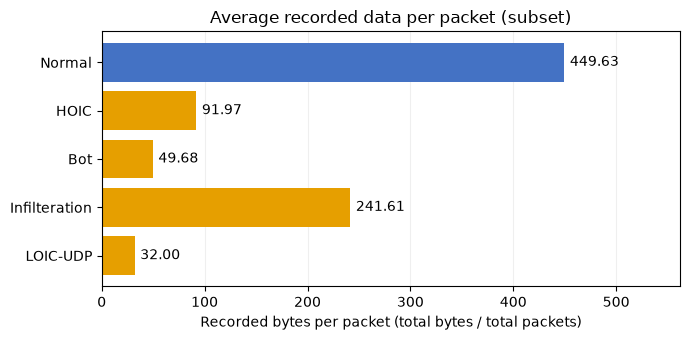

In [38]:
size = chart_data["bytes_per_packet"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(traffic_labels, size, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title(f"Average recorded data per packet ({mode})")
ax.set_xlabel("Recorded bytes per packet (total bytes / total packets)")
ax.set_xlim(0, size.max() * 1.25)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(charts_folder / "bytes_per_packet.png", dpi=160, bbox_inches="tight")
plt.show()


#### Graph 1B:  Packet rate

In this graph we show the middle value (approximate median) of the packets-per-second rates for each traffic record (flow).

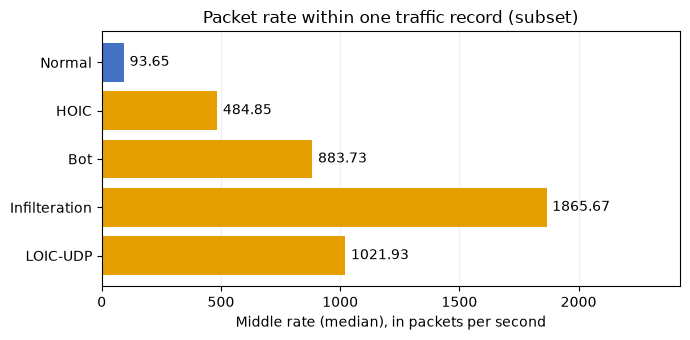

In [39]:
rate = chart_data["median_packets_s"]
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(traffic_labels, rate, color=colors)
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set_title(f"Packet rate within one traffic record ({mode})")
ax.set_xlabel("Middle rate (median), in packets per second")
ax.set_xlim(0, rate.max() * 1.3)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(charts_folder / "packet_rate.png", dpi=160, bbox_inches="tight")
plt.show()


### Question 2: Which network services and traffic characteristics are associated with different attack categories?

In this Graph 2A compares registered service ports. Graph 2B compares normal and attack activity on the same port and protocol.

we are reading the service summary. Percentages include all records in the labels Other includes destinations outside the five named groups.

In [40]:
service_results = pd.read_csv(reports_folder / "analysis" / "service_patterns.csv")
service_order = ["FTP (21/TCP)", "SSH (22/TCP)", "HTTP (80/TCP)",
                 "HTTP-alt (8080/TCP)", "DNS (53/UDP)", "Other"]
row_order = ["Benign", "FTP-BruteForce", "SSH-Bruteforce", "Bot",
              "DDOS attack-HOIC", "Infilteration"]
service_shares = service_results.pivot(index="label", columns="service", values="percent_of_label")
# A pair with no records has a zero share.
service_shares = service_shares.reindex(index=row_order, columns=service_order).fillna(0)
charts_folder = reports_folder / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)


#### Graph 2A:  Services by traffic category

we are reading each row across, darker cells in our graph means a larger percentage of that category. Each row totals 100% before rounding And displayed 0.0 may be a small nonzero value.

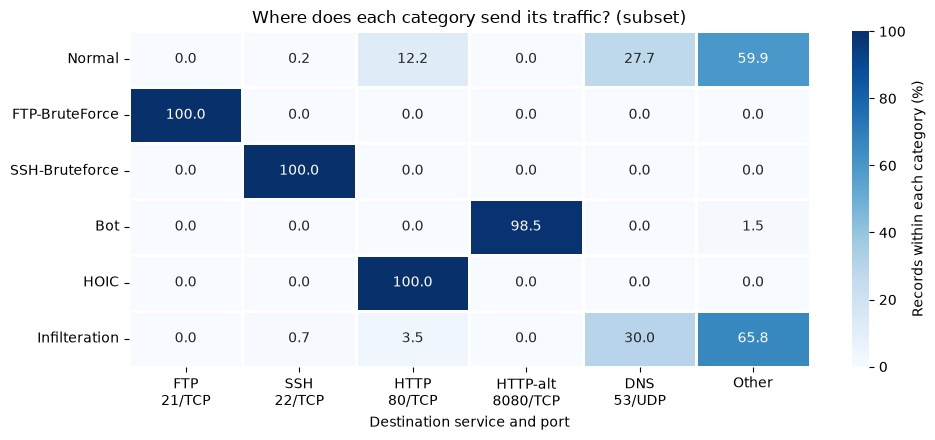

In [41]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(service_shares, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            linewidths=1, cbar_kws={"label": "Records within each category (%)"}, ax=ax)
ax.set_yticklabels(["Normal", "FTP-BruteForce", "SSH-Bruteforce", "Bot", "HOIC", "Infilteration"], rotation=0)
ax.set_xticklabels(["FTP\n21/TCP", "SSH\n22/TCP", "HTTP\n80/TCP", "HTTP-alt\n8080/TCP", "DNS\n53/UDP", "Other"], rotation=0)
ax.set_title(f"Where does each category send its traffic? ({mode})")
ax.set_xlabel("Destination service and port")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(charts_folder / "attack_services.png", dpi=160, bbox_inches="tight")
plt.show()


#### Graph 2B:  Normal and attack records per active minute

In this Graph blue is normal traffic and orange is the named attack. so the bar labels show records per active minute titles show attack rate divided by normal rate.

In [42]:
# Compare normal and attack records on the same service.
attack_services = [("FTP-BruteForce", "FTP (21/TCP)"), ("SSH-Bruteforce", "SSH (22/TCP)"),
                   ("Bot", "HTTP-alt (8080/TCP)"), ("DDOS attack-HOIC", "HTTP (80/TCP)")]
service_rows = service_results.set_index(["label", "service"])
activity_rows = []

for attack, service in attack_services:
    normal = service_rows.loc[("Benign", service)]
    attack_data = service_rows.loc[(attack, service)]
    normal_rate = normal["flows"] / normal["active_minutes"]
    attack_rate = attack_data["flows"] / attack_data["active_minutes"]
    attack_name = "HOIC" if attack == "DDOS attack-HOIC" else attack
    activity_rows.append({
        "Service": service,
        "Attack category": attack_name,
        "Normal records/min": normal_rate,
        "Attack records/min": attack_rate,
    })

activity = pd.DataFrame(activity_rows)
activity["Times normal"] = (activity["Attack records/min"] / activity["Normal records/min"]).map("{:.0f}x".format)


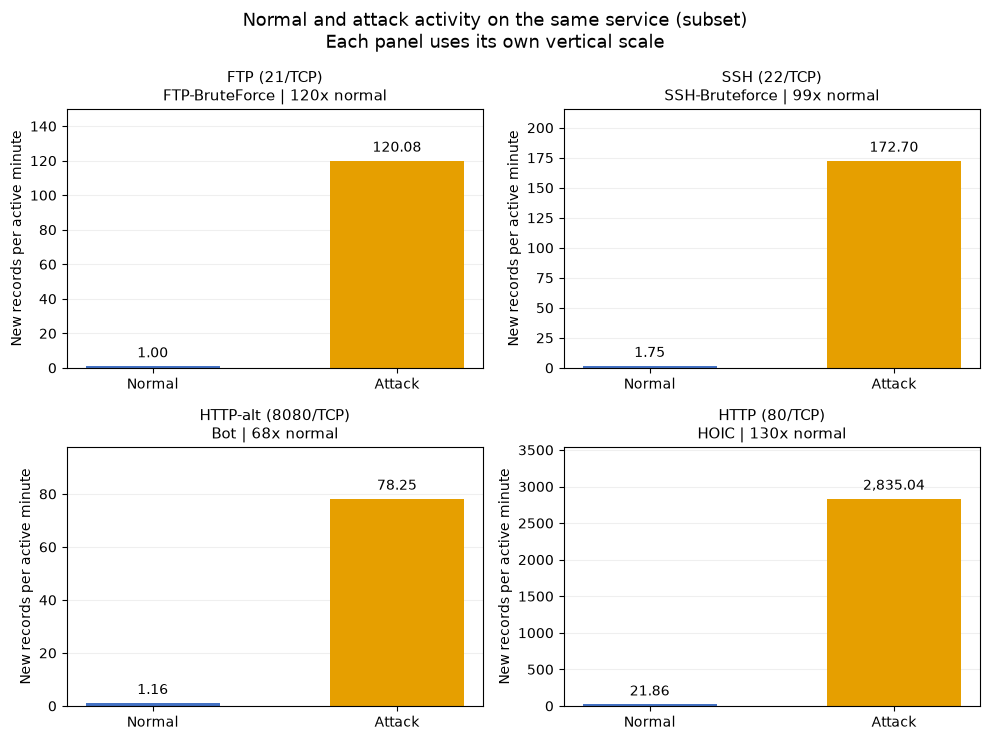

In [43]:
# Each panel has its own scale, so read the printed values.
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
fig.suptitle(f"Normal and attack activity on the same service ({mode})\nEach panel uses its own vertical scale", fontsize=13)

for ax, row in zip(axes.flat, activity.to_dict("records")):
    values = [row["Normal records/min"], row["Attack records/min"]]
    bars = ax.bar(["Normal", "Attack"], values, color=["#4472C4", "#E69F00"], width=0.55)
    ax.bar_label(bars, labels=[f"{value:,.2f}" for value in values], padding=4)
    ax.set_title(f'{row["Service"]}\n{row["Attack category"]} | {row["Times normal"]} normal', fontsize=11)
    ax.set_ylabel("New records per active minute")
    ax.set_ylim(0, max(values) * 1.25)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
fig.savefig(charts_folder / "service_activity.png", dpi=160, bbox_inches="tight")
plt.show()


## Step 8: Stopping Spark

In [44]:
# Stopping spark in the end

spark.stop()